# Task 1: Plot Confusion Matrix (Family-Ordered)

## Mục tiêu
- Load confusion matrix raw (alphabetical order)
- Re-index sang Family order (Cupressaceae first)
- Vẽ confusion matrix với highlight đúng:
  - Khoanh đỏ 8 hàng Cupressaceae (toàn bộ chiều ngang)
  - Species được sắp xếp theo Family

## Requirements
- Đã chạy notebook `01_generate_confusion_matrix.ipynb`
- File `outputs/confusion_matrix_raw.npy` đã tồn tại

---
## Cell 1: Setup & Imports

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Paths
OUTPUT_DIR = Path.cwd().parent / "outputs"
CM_RAW = OUTPUT_DIR / "confusion_matrix_raw.npy"

print(f"Output directory: {OUTPUT_DIR}")
print(f"Raw CM exists: {CM_RAW.exists()}")

Output directory: D:\do_an\woodbench\3 task\task1\outputs
Raw CM exists: True


---
## Cell 2: Define Species Orders

In [2]:
# 17 species - ALPHABETICAL ORDER (như model đã train)
SPECIES_ALPHA = [
    "Araucaria araucana",
    "Callitris columellaris",
    "Calocedrus rupestris",
    "Chamaecyparis obtusa",
    "Cryptomeria japonica",
    "Cunninghamia lanceolata",
    "Fokienia hodginsii",
    "Picea glauca",
    "Pinus cernua",
    "Pinus dalatensis",
    "Pinus krempfii",
    "Pinus radiata",
    "Podocarpus pilgeri",
    "Pseudotsuga brevifolia",
    "Taxus wallichiana",
    "Thujopsis dolabrata",
    "Xanthocyparis vietnamensis",
]

# 17 species - FAMILY ORDER (Cupressaceae first)
SPECIES_FAMILY = [
    # Cupressaceae (8 species)
    "Callitris columellaris",
    "Calocedrus rupestris",
    "Chamaecyparis obtusa",
    "Cryptomeria japonica",
    "Cunninghamia lanceolata",
    "Fokienia hodginsii",
    "Thujopsis dolabrata",
    "Xanthocyparis vietnamensis",
    # Pinaceae (7 species)
    "Araucaria araucana",
    "Picea glauca",
    "Pinus cernua",
    "Pinus dalatensis",
    "Pinus krempfii",
    "Pinus radiata",
    "Pseudotsuga brevifolia",
    # Podocarpaceae (1 species)
    "Podocarpus pilgeri",
    # Taxaceae (1 species)
    "Taxus wallichiana",
]

print(f"Total species: {len(SPECIES_ALPHA)}")
print(f"\nFamily groups:")
print(f"  Cupressaceae: indices 0-7 (8 species)")
print(f"  Pinaceae: indices 8-14 (7 species)")
print(f"  Podocarpaceae: index 15 (1 species)")
print(f"  Taxaceae: index 16 (1 species)")

Total species: 17

Family groups:
  Cupressaceae: indices 0-7 (8 species)
  Pinaceae: indices 8-14 (7 species)
  Podocarpaceae: index 15 (1 species)
  Taxaceae: index 16 (1 species)


---
## Cell 3: Load Raw Confusion Matrix

In [3]:
# Load confusion matrix gốc (alphabetical order)
if not CM_RAW.exists():
    raise FileNotFoundError(
        f"File not found: {CM_RAW}\n"
        "Chạy notebook 01_generate_confusion_matrix.ipynb trước!"
    )

cm_alpha = np.load(CM_RAW)
print(f"[OK] Loaded raw confusion matrix: {cm_alpha.shape}")
print(f"     Total samples: {cm_alpha.sum()}")
print(f"     Correct predictions: {cm_alpha.diagonal().sum()}")
print(f"     Accuracy: {100 * cm_alpha.diagonal().sum() / cm_alpha.sum():.2f}%")

[OK] Loaded raw confusion matrix: (17, 17)
     Total samples: 532
     Correct predictions: 497
     Accuracy: 93.42%


---
## Cell 4: Re-index Confusion Matrix

In [4]:
def reindex_confusion_matrix(cm_alpha, species_alpha, species_family):
    """
    Re-index confusion matrix từ alphabetical order sang family order.
    
    Args:
        cm_alpha: Confusion matrix với alphabetical order (17x17)
        species_alpha: List species theo alphabetical order
        species_family: List species theo family order
        
    Returns:
        cm_family: Confusion matrix với family order (17x17)
    """
    n = len(species_alpha)
    cm_family = np.zeros((n, n), dtype=int)
    
    # Tạo mapping từ alphabetical index -> family index
    alpha_to_idx = {name: i for i, name in enumerate(species_alpha)}
    family_to_idx = {name: i for i, name in enumerate(species_family)}
    
    # Reindex: cm_family[i_new, j_new] = cm_alpha[i_old, j_old]
    for i_new, name_i in enumerate(species_family):
        i_old = alpha_to_idx[name_i]
        for j_new, name_j in enumerate(species_family):
            j_old = alpha_to_idx[name_j]
            cm_family[i_new, j_new] = cm_alpha[i_old, j_old]
    
    return cm_family

# Re-index
cm_family = reindex_confusion_matrix(cm_alpha, SPECIES_ALPHA, SPECIES_FAMILY)
print(f"[OK] Re-indexed confusion matrix to family order")
print(f"     Shape: {cm_family.shape}")
print(f"     Cupressaceae block (8x8): rows 0-7, cols 0-7")

# Save re-indexed matrix
cm_reindexed_path = OUTPUT_DIR / "confusion_matrix_reindexed.npy"
np.save(cm_reindexed_path, cm_family)
print(f"[OK] Saved: {cm_reindexed_path}")

[OK] Re-indexed confusion matrix to family order
     Shape: (17, 17)
     Cupressaceae block (8x8): rows 0-7, cols 0-7
[OK] Saved: D:\do_an\woodbench\3 task\task1\outputs\confusion_matrix_reindexed.npy


---
## Cell 5: Plot Confusion Matrix (Family-Ordered)

[OK] Confusion matrix plotted


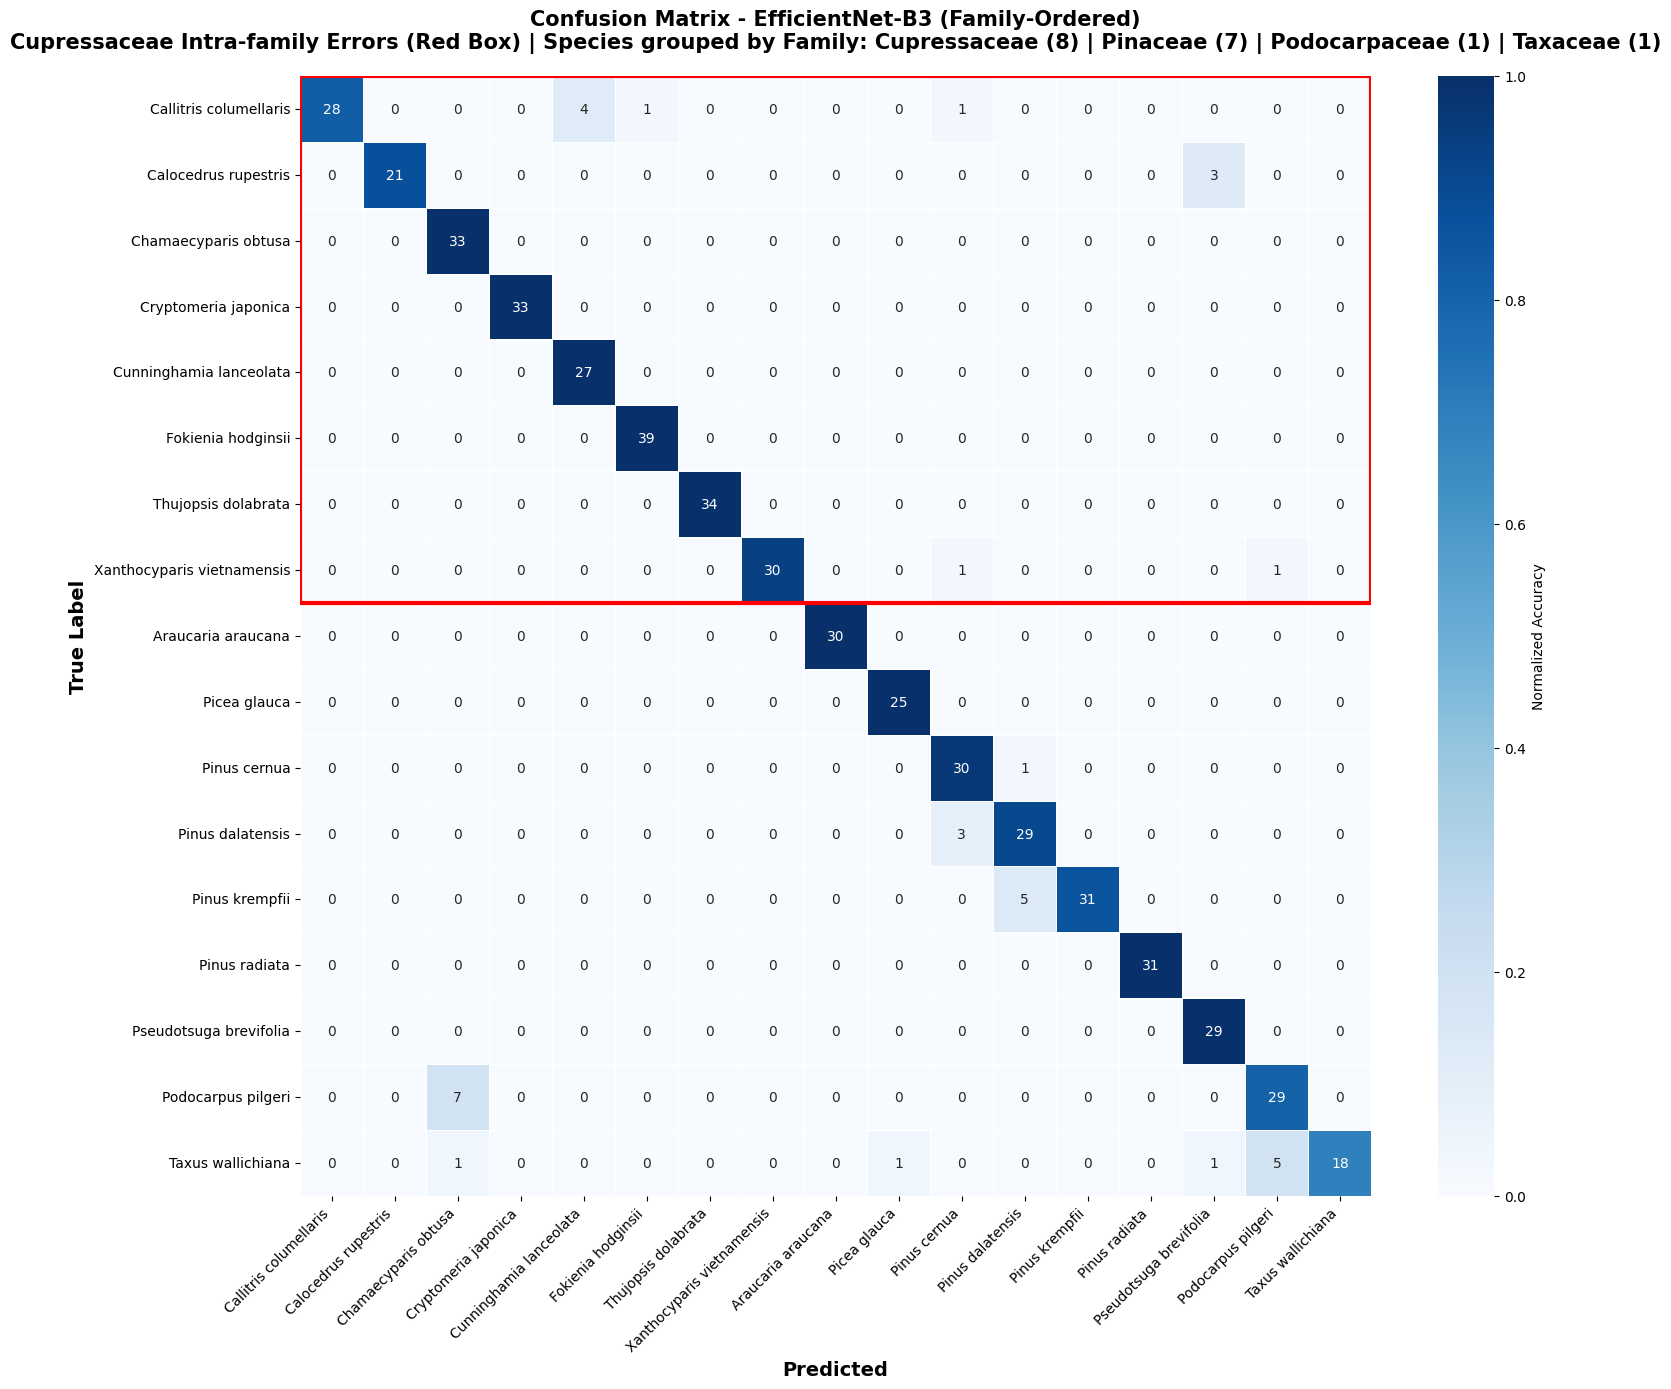

In [5]:
# Vẽ confusion matrix với Family order
fig, ax = plt.subplots(figsize=(16, 14))

# Normalize confusion matrix (theo hàng)
cm_norm = cm_family.astype('float') / cm_family.sum(axis=1)[:, np.newaxis]
cm_norm = np.nan_to_num(cm_norm)  # Handle division by zero

# Vẽ heatmap
sns.heatmap(
    cm_norm,
    annot=cm_family,  # Hiển thị số lượng thật
    fmt='d',
    cmap='Blues',
    xticklabels=SPECIES_FAMILY,
    yticklabels=SPECIES_FAMILY,
    cbar_kws={'label': 'Normalized Accuracy'},
    ax=ax,
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor='white'
)

# Highlight CUPRESSACEAE ROWS (hàng 0-7, toàn bộ cột)
from matplotlib.patches import Rectangle
cupressaceae_box = Rectangle(
    (0, 0),  # (x, y) góc trái dưới
    17,      # width = 17 cột (toàn bộ)
    8,       # height = 8 hàng Cupressaceae
    linewidth=3,
    edgecolor='red',
    facecolor='none'
)
ax.add_patch(cupressaceae_box)

# Formatting
ax.set_xlabel('Predicted', fontsize=14, fontweight='bold')
ax.set_ylabel('True Label', fontsize=14, fontweight='bold')
ax.set_title(
    'Confusion Matrix - EfficientNet-B3 (Family-Ordered)\n'
    'Cupressaceae Intra-family Errors (Red Box) | Species grouped by Family: Cupressaceae (8) | Pinaceae (7) | Podocarpaceae (1) | Taxaceae (1)',
    fontsize=15,
    fontweight='bold',
    pad=20
)

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()

print("[OK] Confusion matrix plotted")

---
## Cell 6: Save Outputs

In [6]:
# Save PNG và PDF
png_path = OUTPUT_DIR / "confusion_matrix_family_ordered.png"
pdf_path = OUTPUT_DIR / "confusion_matrix_family_ordered.pdf"

fig.savefig(png_path, dpi=300, bbox_inches='tight')
fig.savefig(pdf_path, bbox_inches='tight')

print("=" * 70)
print("DONE! Confusion matrix family-ordered")
print("=" * 70)
print(f"Outputs:")
print(f"  - {png_path}")
print(f"  - {pdf_path}")
print(f"  - {cm_reindexed_path}")
print()
print("Highlight đỏ: 8 hàng Cupressaceae (toàn bộ chiều ngang)")
print("Species order: Cupressaceae → Pinaceae → Podocarpaceae → Taxaceae")
print("=" * 70)

DONE! Confusion matrix family-ordered
Outputs:
  - D:\do_an\woodbench\3 task\task1\outputs\confusion_matrix_family_ordered.png
  - D:\do_an\woodbench\3 task\task1\outputs\confusion_matrix_family_ordered.pdf
  - D:\do_an\woodbench\3 task\task1\outputs\confusion_matrix_reindexed.npy

Highlight đỏ: 8 hàng Cupressaceae (toàn bộ chiều ngang)
Species order: Cupressaceae → Pinaceae → Podocarpaceae → Taxaceae


---
## Cell 7: Analysis - Cupressaceae Errors

In [7]:
# Phân tích lỗi Cupressaceae
print("=" * 70)
print("CUPRESSACEAE ERROR ANALYSIS")
print("=" * 70)

# Lấy khối Cupressaceae (8x8)
cm_cupress = cm_family[:8, :8]
total_cupress = cm_cupress.sum()
correct_cupress = cm_cupress.diagonal().sum()
errors_cupress = total_cupress - correct_cupress

print(f"\nIntra-family (Cupressaceae 8x8 block):")
print(f"  Total samples: {total_cupress}")
print(f"  Correct: {correct_cupress}")
print(f"  Errors (intra-family): {errors_cupress}")
print(f"  Intra-family accuracy: {100 * correct_cupress / total_cupress:.2f}%")

# Lỗi ra ngoài họ
cm_cupress_full = cm_family[:8, :]  # 8 hàng Cupressaceae, toàn bộ cột
total_cupress_full = cm_cupress_full.sum()
errors_inter_family = cm_cupress_full[:, 8:].sum()  # Lỗi sang các họ khác

print(f"\nInter-family (Cupressaceae → other families):")
print(f"  Errors to Pinaceae: {cm_cupress_full[:, 8:15].sum()}")
print(f"  Errors to Podocarpaceae: {cm_cupress_full[:, 15].sum()}")
print(f"  Errors to Taxaceae: {cm_cupress_full[:, 16].sum()}")
print(f"  Total inter-family errors: {errors_inter_family}")

print(f"\nSummary:")
print(f"  Intra-family errors: {errors_cupress} ({100 * errors_cupress / total_cupress_full:.2f}%)")
print(f"  Inter-family errors: {errors_inter_family} ({100 * errors_inter_family / total_cupress_full:.2f}%)")
print("=" * 70)

CUPRESSACEAE ERROR ANALYSIS

Intra-family (Cupressaceae 8x8 block):
  Total samples: 250
  Correct: 245
  Errors (intra-family): 5
  Intra-family accuracy: 98.00%

Inter-family (Cupressaceae → other families):
  Errors to Pinaceae: 5
  Errors to Podocarpaceae: 1
  Errors to Taxaceae: 0
  Total inter-family errors: 6

Summary:
  Intra-family errors: 5 (1.95%)
  Inter-family errors: 6 (2.34%)
